# PS-39: Handwritten Tamil Character Recognition (HPL IWFHR-06, offline)
**RA2311026050034**

**Task:** classify isolated offline (bi-level TIFF) handwritten Tamil characters into 156 classes.

**Specific challenge addressed:** *confusable characters* (differ by one small stroke) and *writer leakage*.

**Novelty (CGER – Confusion-Guided Expert Refinement):**
1. Writer-disjoint train/validation split (the train folders `usr_*` are writers) so validation is not inflated by seeing the same writer's style.
2. Train a stage-1 CNN, then mine confusable class groups from the *validation* confusion matrix.
3. Fine-tune a small *expert* per confusable group and fuse expert + stage-1 probabilities only where stage-1 is uncertain.
4. Stroke-preserving augmentation (no erasing/cutout/erosion, which could delete the tiny distinguishing stroke).

Prior work this builds on is listed in the report (Vijayaraghavan & Sra CNN; uTHCD benchmark CNNs; TamHNet / multi-attention CNN;
Ramakrishnan & Sundaram sub-stroke post-processing of confused *online* characters). The gap: offline CNN papers report overall accuracy
only and use one flat softmax for all 156 classes; none mines confusion groups from the model itself and refines them.

In [90]:
import os, re, json, copy, math, random, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from joblib import Parallel, delayed
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score
from tqdm.auto import tqdm

SEED = 42
QUICK = os.environ.get("PS39_QUICK") == "1"          # tiny smoke-test mode
ROOT = Path(os.environ.get("PS39_ROOT", ".")).resolve()
DATA = ROOT / "dataset"
TRAIN_DIR = DATA / "train" / "hpl-tamil-iwfhr06-train-offline"
TEST_DIR = DATA / "test" / "hpl-tamil-iwfhr06-test-offline"
GT_FILE = DATA / "hpl-tamil-iwfhr06-test-groundtruth.txt"
OUT = ROOT / "outputs"; EXP = OUT / "experiments"; EXPERTS = OUT / "experts"
for d in (OUT, EXP, EXPERTS): d.mkdir(parents=True, exist_ok=True)

IMG = 64
BS = 128
EPOCHS = 2 if QUICK else 30
EPOCHS_RESNET = 2 if QUICK else 15
EPOCHS_EXPERT = 1 if QUICK else 8
RUN_RESNET = (not QUICK)          # ImageNet-pretrained ResNet-18 comparison (needs internet for weights)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
print("device:", DEV, "| root:", ROOT, "| quick:", QUICK)

device: cuda | root: C:\Users\Shreya\Projects\RA2311026050034_PS39 | quick: False


## 1. Load data, build metadata
Train file name `CCCtNN.tiff` → `CCC` is the class id, `NN` the sample index; the parent folder `usr_XXX` is the writer.
Test labels come from the ground-truth text file.

In [91]:
def build_train_meta():
    rows = []
    for wdir in sorted(p for p in TRAIN_DIR.iterdir() if p.is_dir()):
        for f in sorted(wdir.iterdir()):
            if f.suffix.lower() in (".tif", ".tiff"):
                m = re.match(r"(\d+)t(\d+)", f.stem)
                if m:
                    rows.append(dict(path=str(f), writer=wdir.name, raw_label=int(m.group(1)), sample=int(m.group(2))))
    return pd.DataFrame(rows)

def build_test_meta():
    files = sorted(f for f in TEST_DIR.iterdir() if f.suffix.lower() in (".tif", ".tiff"))
    lines = [l.split() for l in GT_FILE.read_text().splitlines() if l.strip()]
    print("ground-truth head:", lines[:3])
    by_name = {}
    if all(any(".tif" in t.lower() for t in l) for l in lines):
        for l in lines:
            name = next(t for t in l if ".tif" in t.lower())
            by_name[Path(name).stem] = int(l[-1] if l[-1] != name else l[0])
        rows = [dict(path=str(f), raw_label=by_name[f.stem]) for f in files if f.stem in by_name]
    else:                                                    # fall back to line order == sorted file order
        assert len(lines) == len(files), f"GT lines {len(lines)} != files {len(files)}"
        rows = [dict(path=str(f), raw_label=int(l[-1])) for f, l in zip(files, lines)]
    return pd.DataFrame(rows)

train_meta, test_meta = build_train_meta(), build_test_meta()
classes = sorted(train_meta.raw_label.unique())
assert set(test_meta.raw_label) <= set(classes), "test has labels unseen in train"
cls2idx = {c: i for i, c in enumerate(classes)}
train_meta["label"] = train_meta.raw_label.map(cls2idx)
test_meta["label"] = test_meta.raw_label.map(cls2idx)
N_CLS = len(classes)
train_meta.to_csv(ROOT / "train_metadata.csv", index=False); test_meta.to_csv(ROOT / "test_metadata.csv", index=False)
print(f"classes: {N_CLS} | train images: {len(train_meta)} from {train_meta.writer.nunique()} writers | test images: {len(test_meta)}")

ground-truth head: [['00000', '98'], ['00001', '108'], ['00002', '84']]
classes: 156 | train images: 50683 from 117 writers | test images: 26926


### Images per class

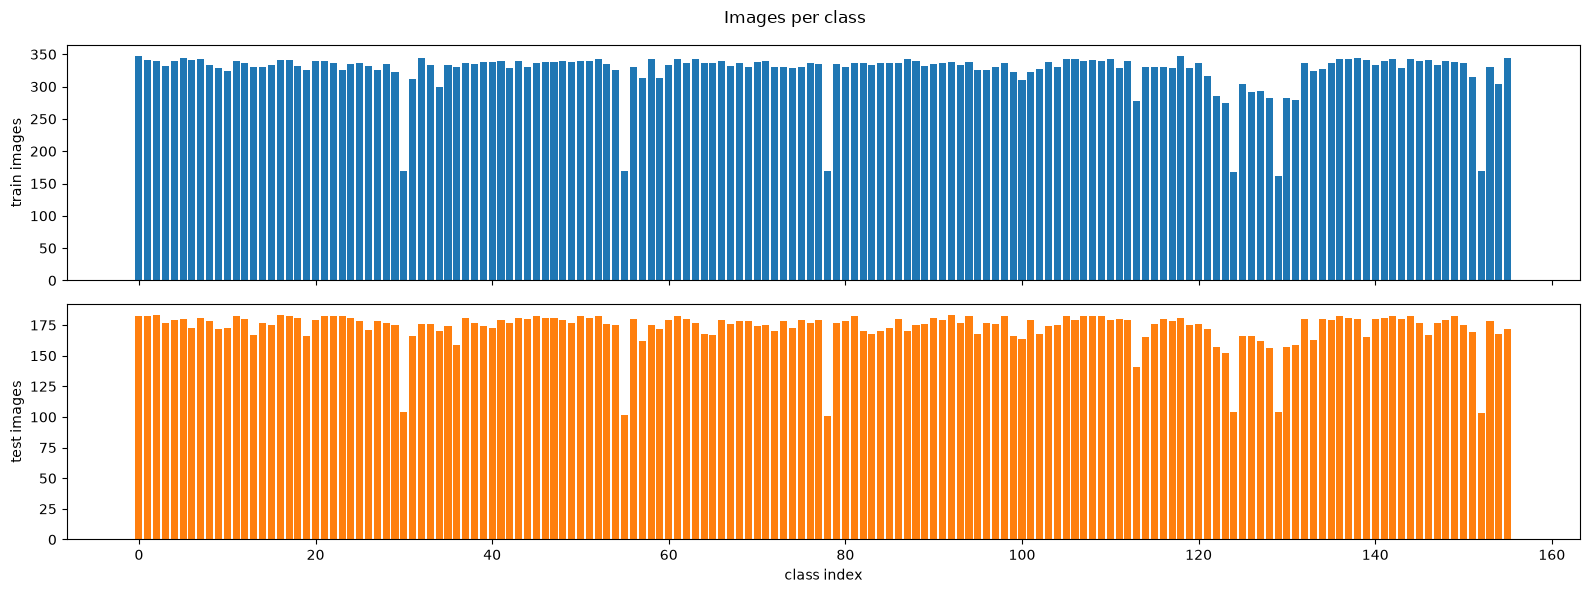

       train   test
count  156.0  156.0
mean   324.9  172.6
std     34.4   15.6
min    162.0  101.0
25%    329.0  171.8
50%    335.0  177.0
75%    339.0  180.0
max    347.0  183.0
imbalance ratio (max/min train count): 2.14


In [92]:
cnt_tr = train_meta.label.value_counts().sort_index()
cnt_te = test_meta.label.value_counts().reindex(range(N_CLS), fill_value=0)
fig, ax = plt.subplots(2, 1, figsize=(16, 6), sharex=True)
ax[0].bar(range(N_CLS), cnt_tr.reindex(range(N_CLS), fill_value=0).values); ax[0].set_ylabel("train images")
ax[1].bar(range(N_CLS), cnt_te.values, color="tab:orange"); ax[1].set_ylabel("test images"); ax[1].set_xlabel("class index")
plt.suptitle("Images per class"); plt.tight_layout(); plt.savefig(EXP / "class_counts.png", dpi=120); plt.show()
print(pd.DataFrame({"train": cnt_tr.describe(), "test": cnt_te.describe()}).round(1))
print("imbalance ratio (max/min train count): %.2f" % (cnt_tr.max() / cnt_tr.min()))
pd.DataFrame({"class_index": range(N_CLS), "class_id": classes, "train": cnt_tr.reindex(range(N_CLS), fill_value=0).values,
              "test": cnt_te.values}).to_csv(EXP / "images_per_class.csv", index=False)

## 2. Pre-processing → cached arrays
Bi-level TIFF → ink mask (ink = minority colour) → crop to ink bounding box → pad to square → resize to 64×64.
Strokes are white (255) on black (0). Cropping+square padding removes position/scale nuisance while keeping aspect ratio,
which matters because some characters differ by relative size/placement of a small component.

In [93]:
def load_img(path, size=IMG, margin=0.08):
    a = np.asarray(Image.open(path).convert("L"))
    dark = a <= 127
    ink = dark if dark.mean() < 0.5 else ~dark
    ys, xs = np.where(ink)
    if len(ys) == 0:
        return np.zeros((size, size), np.uint8)
    ink = ink[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    h, w = ink.shape; s = int(round(max(h, w) * (1 + 2 * margin)))
    canvas = np.zeros((s, s), np.uint8)
    oy, ox = (s - h) // 2, (s - w) // 2
    canvas[oy:oy + h, ox:ox + w] = ink * 255
    return np.asarray(Image.fromarray(canvas).resize((size, size), Image.BILINEAR))

def load_many(paths):
    arr = Parallel(n_jobs=-1, batch_size=64)(delayed(load_img)(p) for p in tqdm(paths))
    return np.stack(arr)[:, None]                      # [N,1,H,W] uint8

cache = OUT / f"cache_{IMG}.npz"
if cache.exists() and np.load(cache)["Xtr"].shape[0] == len(train_meta) and np.load(cache)["Xte"].shape[0] == len(test_meta):
    z = np.load(cache); Xall, Xte = z["Xtr"], z["Xte"]
else:
    Xall, Xte = load_many(train_meta.path), load_many(test_meta.path)
    np.savez_compressed(cache, Xtr=Xall, Xte=Xte)
yall, yte = train_meta.label.values, test_meta.label.values
print(Xall.shape, Xte.shape)

100%|██████████| 26926/26926 [00:02<00:00, 12455.76it/s]


(50683, 1, 64, 64) (26926, 1, 64, 64)


### Sample images (3 per class, all classes, 52 classes per figure)

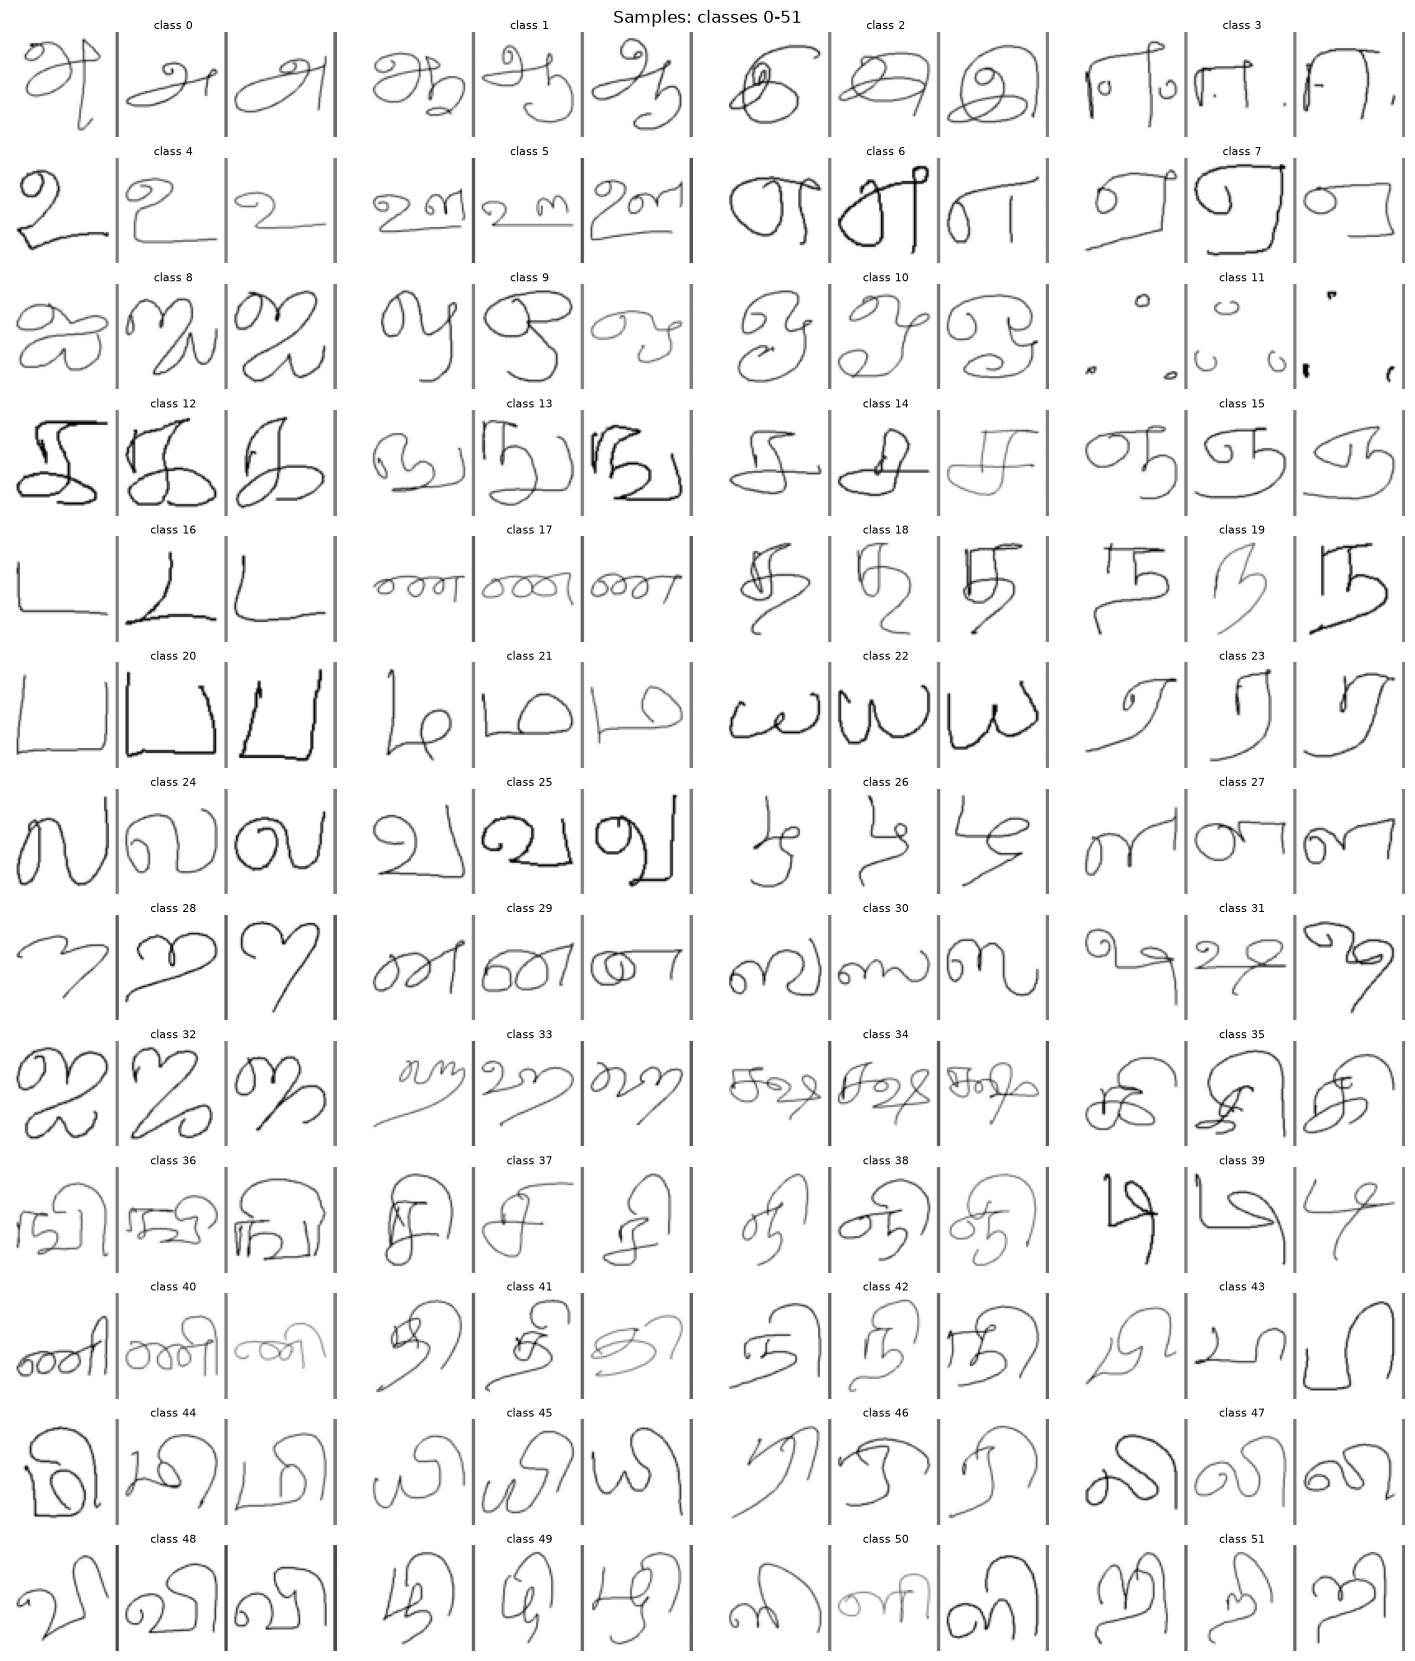

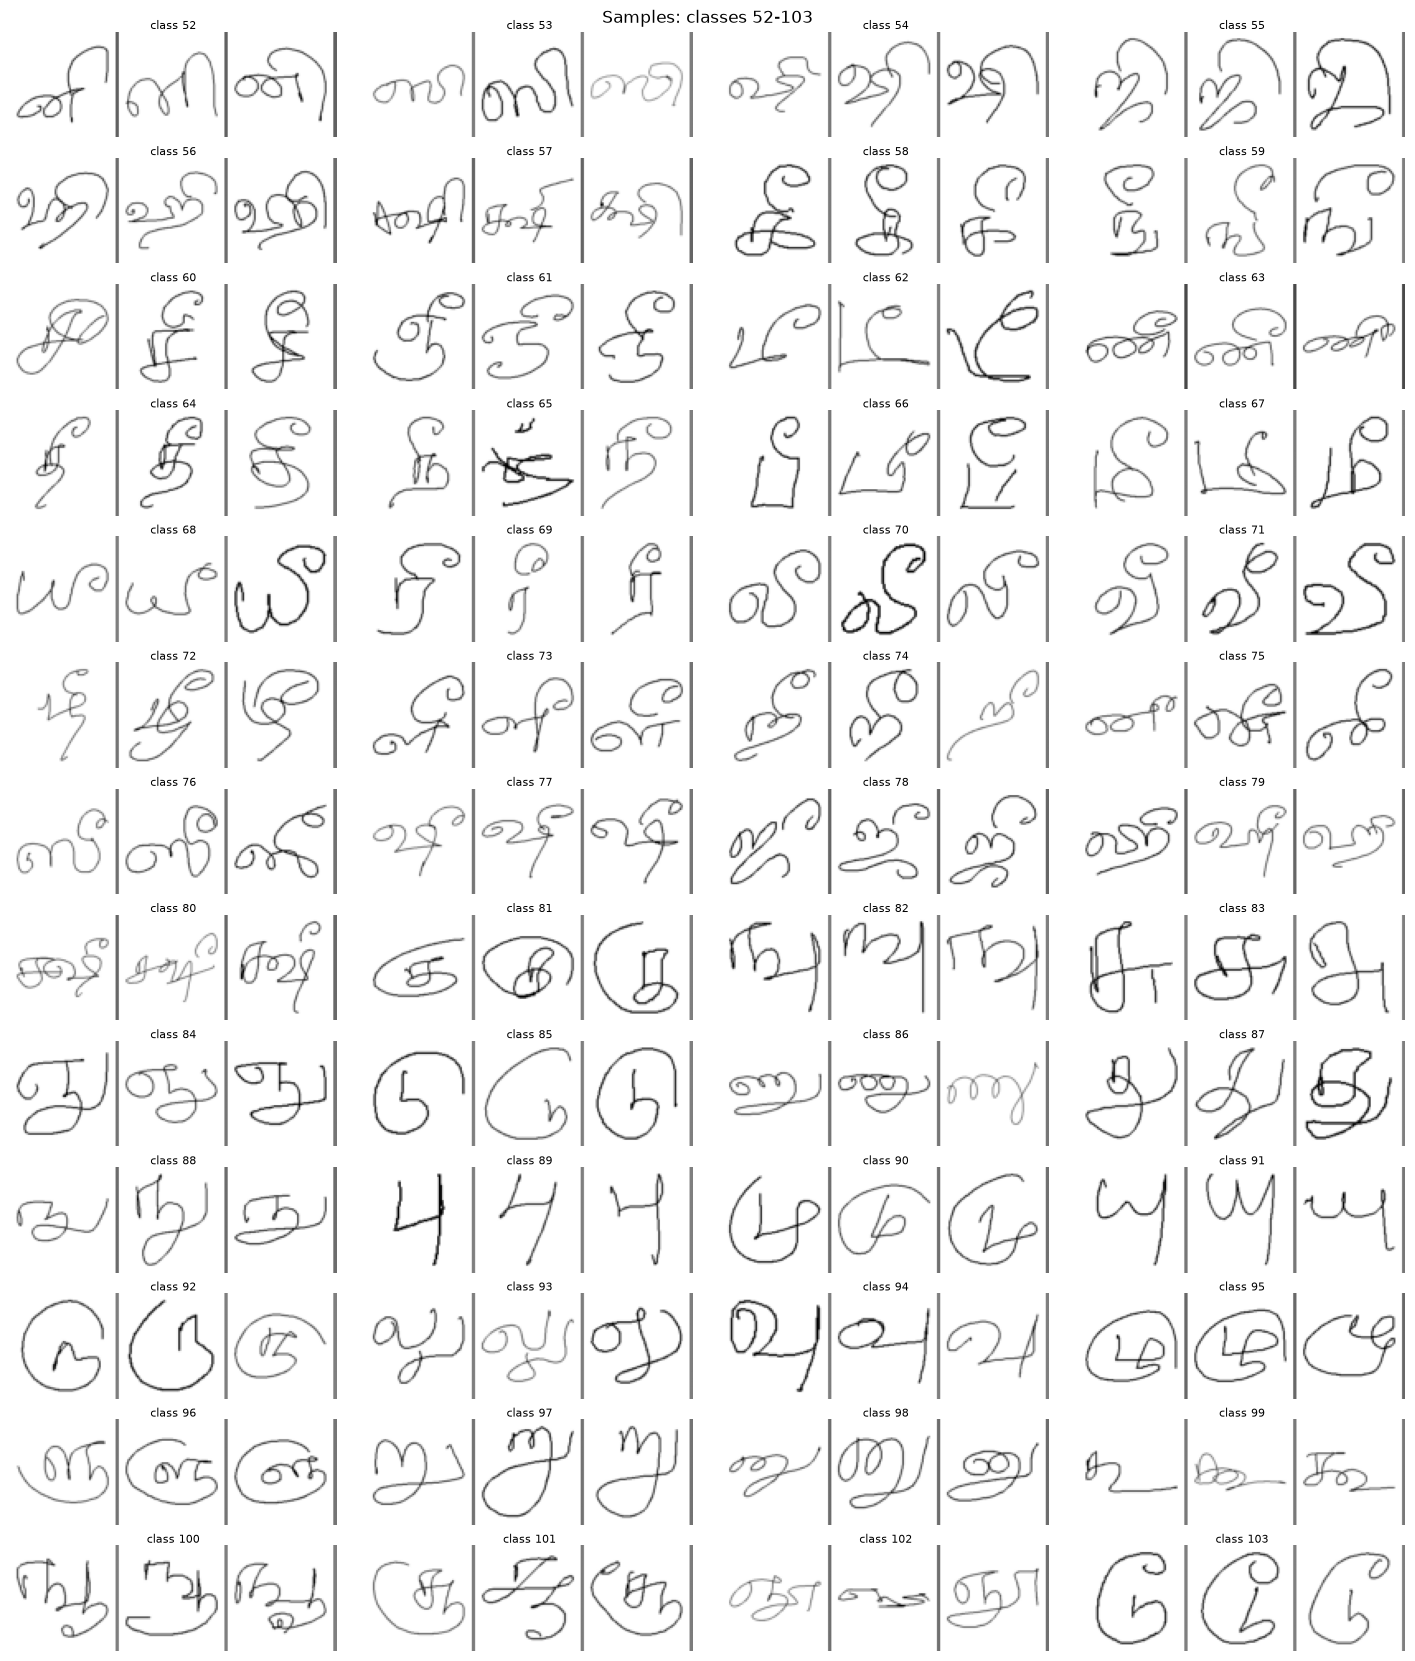

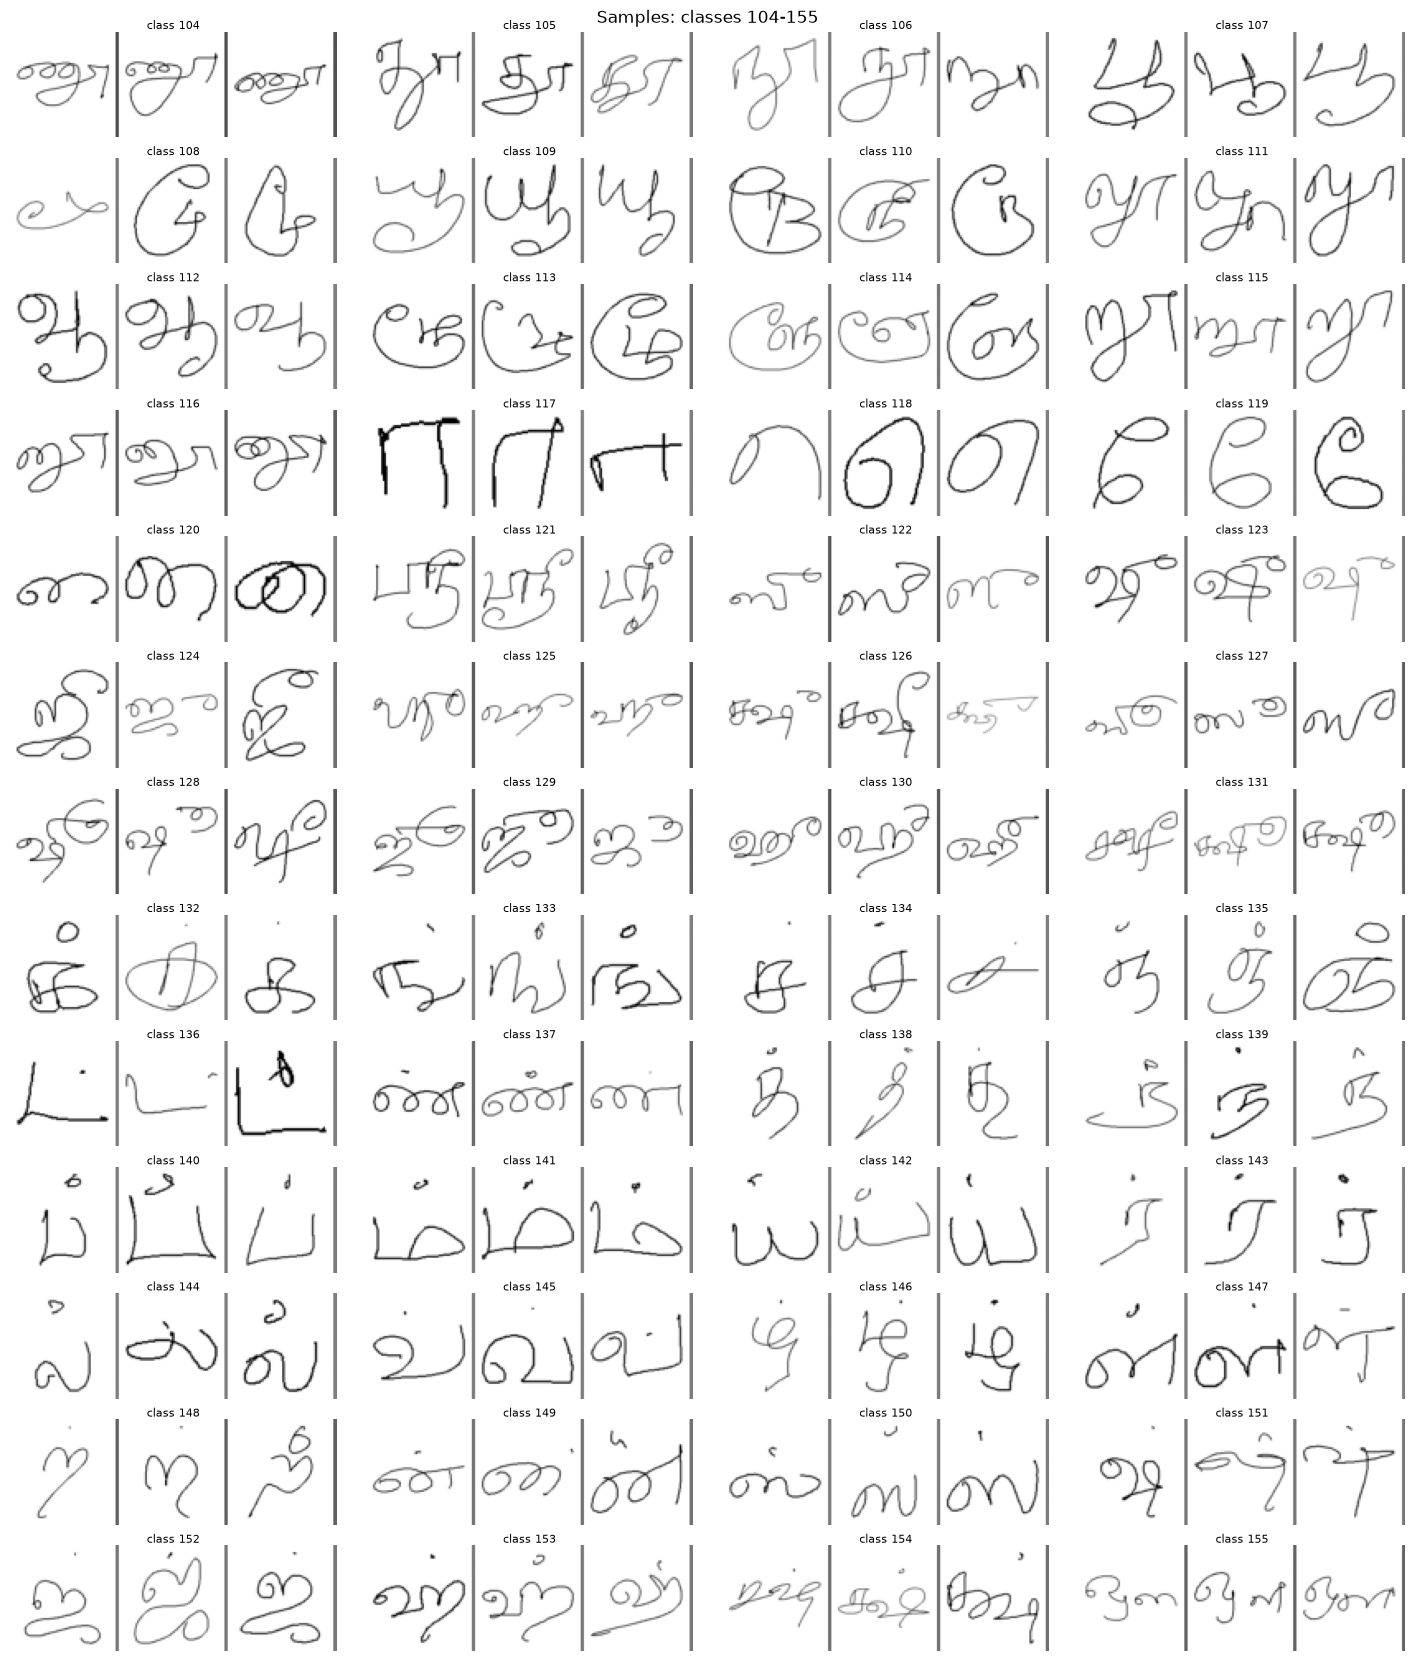

In [94]:
def class_grid(cls_list, title, fname):
    cols = 4; rows = math.ceil(len(cls_list) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 3.6, rows * 1.3))
    for ax in axes.ravel(): ax.axis("off")
    rng = np.random.RandomState(0)
    for ax, c in zip(axes.ravel(), cls_list):
        idx = np.where(yall == c)[0]; idx = rng.choice(idx, min(3, len(idx)), replace=False)
        strip = np.hstack([np.pad(Xall[i, 0], ((0, 0), (0, 2)), constant_values=128) for i in idx])
        ax.imshow(255 - strip, cmap="gray"); ax.set_title(f"class {c}", fontsize=8, pad=1)
    plt.suptitle(title); plt.tight_layout(); plt.savefig(EXP / fname, dpi=110); plt.show()

per = 52
for k in range(0, N_CLS, per):
    class_grid(list(range(k, min(k + per, N_CLS))), f"Samples: classes {k}-{min(k + per, N_CLS) - 1}", f"samples_{k}.png")

## 3. Splits (fixed seed, **writer-disjoint** validation)
The official test set is kept untouched and used once at the end. Validation is carved out of the training writers
by writer id, so no writer appears in both train and validation (prevents style leakage).

In [95]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tr_idx, va_idx = next(gss.split(Xall, yall, groups=train_meta.writer.values))
assert set(train_meta.writer.iloc[tr_idx]).isdisjoint(set(train_meta.writer.iloc[va_idx]))
Xtr, ytr, Xva, yva = Xall[tr_idx], yall[tr_idx], Xall[va_idx], yall[va_idx]
train_meta.iloc[tr_idx].to_csv(ROOT / "train_split.csv", index=False); train_meta.iloc[va_idx].to_csv(ROOT / "validation_split.csv", index=False)
print(f"train {len(Xtr)} ({train_meta.writer.iloc[tr_idx].nunique()} writers) | val {len(Xva)} ({train_meta.writer.iloc[va_idx].nunique()} writers) | test {len(Xte)}")
missing = set(range(N_CLS)) - set(np.unique(yva)); print("classes absent from validation:", sorted(missing))

train 42202 (99 writers) | val 8481 (18 writers) | test 26926
classes absent from validation: []


## 4. Models and training utilities

In [96]:
class CNN(nn.Module):
    """4 conv stages (2×conv-BN-ReLU + pool). Flatten (not GAP) keeps *where* a small stroke sits."""
    def __init__(s, n_cls, widths=(32, 64, 128, 256), p=0.4, img=IMG):
        super().__init__()
        L, c = [], 1
        for o in widths:
            L += [nn.Conv2d(c, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                  nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True), nn.MaxPool2d(2)]
            c = o
        s.features = nn.Sequential(*L)
        f = img // (2 ** len(widths))
        s.embed = nn.Sequential(nn.Flatten(), nn.Linear(c * f * f, 256), nn.BatchNorm1d(256), nn.ReLU(True), nn.Dropout(p))
        s.head = nn.Linear(256, n_cls)
    def forward(s, x): return s.head(s.embed(s.features(x)))

class ResNetWrap(nn.Module):
    """ImageNet-pretrained ResNet-18 adapted to 1-channel 64×64 input."""
    def __init__(s, n_cls):
        super().__init__()
        import torchvision
        try: net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
        except Exception as e: print("pretrained weights unavailable, random init:", e); net = torchvision.models.resnet18(weights=None)
        w = net.conv1.weight.data.sum(1, keepdim=True)
        net.conv1 = nn.Conv2d(1, 64, 3, 1, 1, bias=False)
        net.conv1.weight.data = F.interpolate(w, size=(3, 3), mode="bilinear", align_corners=False)  # RGB kernels summed, resized 7→3
        net.maxpool = nn.Identity(); net.fc = nn.Identity()
        s.net, s.head = net, nn.Linear(512, n_cls)
    def forward(s, x): return s.head(s.net(x))

def make_model(kind, n): return CNN(n) if kind == "cnn" else ResNetWrap(n)

def gpu_augment(x, max_rot=10, scale=(0.9, 1.1), shift=0.08, shear=0.10, p_thick=0.3):
    """Stroke-preserving augmentation: small affine + occasional dilation. No cutout/erasing/erosion (could remove the key stroke)."""
    B, dev = x.size(0), x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * max_rot * math.pi / 180
    sc = torch.empty(B, device=dev).uniform_(*scale)
    sh = (torch.rand(B, device=dev) * 2 - 1) * shear
    tx, ty = (torch.rand(2, B, device=dev) * 2 - 1) * shift
    cos, sin = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([cos, -sin + sh, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    x = F.grid_sample(x, F.affine_grid(theta, x.shape, align_corners=False), padding_mode="zeros", align_corners=False)
    thick = (torch.rand(B, 1, 1, 1, device=dev) < p_thick).float()
    return thick * F.max_pool2d(x, 3, 1, 1) + (1 - thick) * x

@torch.no_grad()
def predict_proba(model, X, bs=512):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEV).float().div_(255)
        with torch.autocast(DEV.type, enabled=DEV.type == "cuda"):
            out.append(F.softmax(model(xb).float(), 1).cpu())
    return torch.cat(out).numpy()

def macro_f1(y, p): return f1_score(y, p, average="macro", labels=np.unique(y), zero_division=0)

def train_model(name, Xtr, ytr, Xva, yva, n_cls, kind="cnn", aug=False, class_weight=None, epochs=EPOCHS,
                lr=2e-3, init=None, bs=BS, save=True, verbose=True):
    seed_all()
    model = (init if init is not None else make_model(kind, n_cls)).to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    bs = int(bs); N = len(Xtr); spe = max(1, N // bs)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * spe)
    cw = None if class_weight is None else torch.tensor(class_weight, dtype=torch.float32, device=DEV)
    crit = nn.CrossEntropyLoss(weight=cw, label_smoothing=0.05)
    scaler = torch.amp.GradScaler("cuda", enabled=DEV.type == "cuda")
    Xg, yg = torch.from_numpy(Xtr).to(DEV), torch.from_numpy(ytr).long().to(DEV)
    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "val_f1")}
    best, best_state = -1, None
    for ep in range(epochs):
        model.train(); perm = torch.randperm(N, device=DEV); tl = tc = tn = 0
        for b in range(spe):
            idx = perm[b * bs:(b + 1) * bs]; xb = Xg[idx].float().div_(255); yb = yg[idx]
            if aug: xb = gpu_augment(xb)
            with torch.autocast(DEV.type, enabled=DEV.type == "cuda"):
                lg = model(xb); loss = crit(lg.float(), yb)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += loss.item() * len(idx); tc += (lg.argmax(1) == yb).sum().item(); tn += len(idx)
        P = predict_proba(model, Xva); pv = P.argmax(1)
        vl = float(-np.log(P[np.arange(len(yva)), yva] + 1e-9).mean()); va = accuracy_score(yva, pv); vf = macro_f1(yva, pv)
        for k, v in zip(hist, (tl / tn, tc / tn, vl, va, vf)): hist[k].append(v)
        if vf > best: best, best_state = vf, copy.deepcopy(model.state_dict())
        if verbose: print(f"[{name}] ep {ep + 1:02d}/{epochs} loss {tl / tn:.3f} acc {tc / tn:.3f} | val loss {vl:.3f} acc {va:.4f} macroF1 {vf:.4f}")
    model.load_state_dict(best_state)
    if save: torch.save(best_state, OUT / f"best_{name}.pth"); json.dump(hist, open(EXP / f"hist_{name}.json", "w"))
    return model, hist

def plot_hist(hists, fname="training_curves.png"):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for n, h in hists.items():
        ax[0].plot(h["train_loss"], "--", label=f"{n} train"); ax[0].plot(h["val_loss"], label=f"{n} val")
        ax[1].plot(h["train_acc"], "--", label=f"{n} train"); ax[1].plot(h["val_acc"], label=f"{n} val")
    ax[0].set_title("Loss"); ax[1].set_title("Accuracy"); [a.set_xlabel("epoch") or a.legend(fontsize=7) for a in ax]
    plt.tight_layout(); plt.savefig(EXP / fname, dpi=120); plt.show()

## 5. Experiments (all selected on the validation set only)
* **A** custom CNN, no augmentation
* **B** custom CNN + stroke-preserving augmentation
* **C** custom CNN + augmentation + class-weighted loss (class imbalance)
* **D** (optional) ImageNet-pretrained ResNet-18 + augmentation

[custom_cnn] ep 01/30 loss 3.669 acc 0.360 | val loss 2.569 acc 0.6464 macroF1 0.6197
[custom_cnn] ep 02/30 loss 1.837 acc 0.780 | val loss 1.018 acc 0.8374 macroF1 0.8305
[custom_cnn] ep 03/30 loss 0.988 acc 0.901 | val loss 0.580 acc 0.8770 macroF1 0.8717
[custom_cnn] ep 04/30 loss 0.815 acc 0.930 | val loss 0.500 acc 0.8852 macroF1 0.8804
[custom_cnn] ep 05/30 loss 0.774 acc 0.938 | val loss 0.628 acc 0.8625 macroF1 0.8544
[custom_cnn] ep 06/30 loss 0.745 acc 0.947 | val loss 0.411 acc 0.8980 macroF1 0.8914
[custom_cnn] ep 07/30 loss 0.713 acc 0.954 | val loss 0.398 acc 0.8987 macroF1 0.8943
[custom_cnn] ep 08/30 loss 0.693 acc 0.958 | val loss 0.495 acc 0.8848 macroF1 0.8801
[custom_cnn] ep 09/30 loss 0.666 acc 0.965 | val loss 0.379 acc 0.9083 macroF1 0.9034
[custom_cnn] ep 10/30 loss 0.638 acc 0.971 | val loss 0.410 acc 0.9074 macroF1 0.9023
[custom_cnn] ep 11/30 loss 0.619 acc 0.976 | val loss 0.380 acc 0.9124 macroF1 0.9082
[custom_cnn] ep 12/30 loss 0.604 acc 0.979 | val loss 

C:\Users\Shreya\AppData\Local\Temp\ipykernel_28656\3180442783.py:76: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()


[resnet18_ft] ep 01/15 loss 2.929 acc 0.543 | val loss 0.955 acc 0.8407 macroF1 0.8259
[resnet18_ft] ep 02/15 loss 0.819 acc 0.924 | val loss 0.426 acc 0.8980 macroF1 0.8915
[resnet18_ft] ep 03/15 loss 0.712 acc 0.939 | val loss 0.442 acc 0.8965 macroF1 0.8853
[resnet18_ft] ep 04/15 loss 0.687 acc 0.942 | val loss 0.373 acc 0.9060 macroF1 0.9015
[resnet18_ft] ep 05/15 loss 0.653 acc 0.951 | val loss 0.368 acc 0.9102 macroF1 0.9055
[resnet18_ft] ep 06/15 loss 0.616 acc 0.959 | val loss 0.364 acc 0.9098 macroF1 0.9035
[resnet18_ft] ep 07/15 loss 0.592 acc 0.963 | val loss 0.315 acc 0.9201 macroF1 0.9143
[resnet18_ft] ep 08/15 loss 0.571 acc 0.969 | val loss 0.313 acc 0.9214 macroF1 0.9178
[resnet18_ft] ep 09/15 loss 0.552 acc 0.973 | val loss 0.294 acc 0.9295 macroF1 0.9243
[resnet18_ft] ep 10/15 loss 0.533 acc 0.976 | val loss 0.299 acc 0.9302 macroF1 0.9258
[resnet18_ft] ep 11/15 loss 0.517 acc 0.981 | val loss 0.303 acc 0.9295 macroF1 0.9248
[resnet18_ft] ep 12/15 loss 0.503 acc 0.985

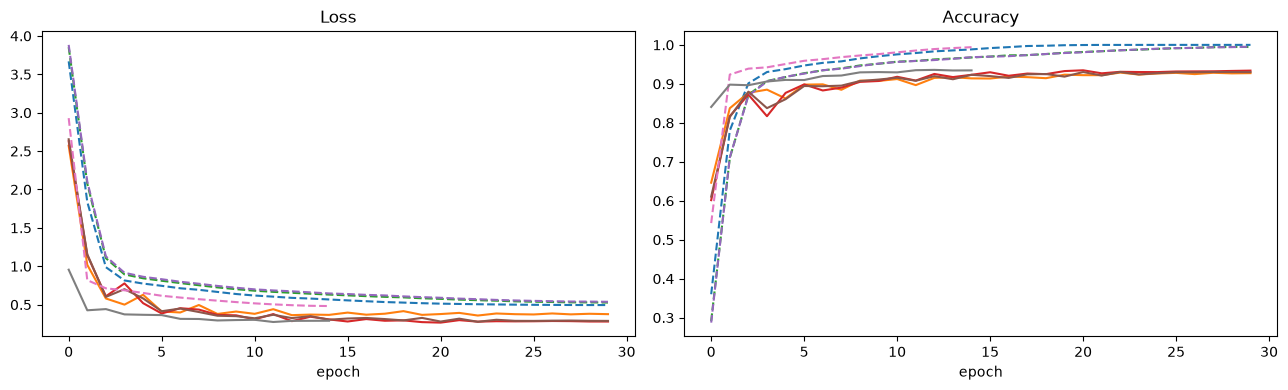

                     best_val_acc  best_val_macroF1  final_train_acc     gap
custom_cnn                 0.9289            0.9247           1.0000  0.0725
custom_cnn_aug             0.9348            0.9305           0.9946  0.0606
custom_cnn_balanced        0.9304            0.9260           0.9953  0.0652
resnet18_ft                0.9359            0.9319           0.9941  0.0596
selected stage-1 model: resnet18_ft


In [97]:
cnt = np.bincount(ytr, minlength=N_CLS).astype(float)
cw_bal = cnt.sum() / (N_CLS * np.maximum(cnt, 1)); cw_bal = cw_bal / cw_bal.mean()
models, hists = {}, {}
models["custom_cnn"], hists["custom_cnn"] = train_model("custom_cnn", Xtr, ytr, Xva, yva, N_CLS, aug=False)
models["custom_cnn_aug"], hists["custom_cnn_aug"] = train_model("custom_cnn_aug", Xtr, ytr, Xva, yva, N_CLS, aug=True)
models["custom_cnn_balanced"], hists["custom_cnn_balanced"] = train_model("custom_cnn_balanced", Xtr, ytr, Xva, yva, N_CLS, aug=True, class_weight=cw_bal)
if RUN_RESNET:
    models["resnet18_ft"], hists["resnet18_ft"] = train_model("resnet18_ft", Xtr, ytr, Xva, yva, N_CLS, kind="resnet", aug=True, epochs=EPOCHS_RESNET, lr=1e-3)
plot_hist(hists)

summ = pd.DataFrame({n: dict(best_val_acc=max(h["val_acc"]), best_val_macroF1=max(h["val_f1"]), final_train_acc=h["train_acc"][-1],
                              gap=h["train_acc"][-1] - h["val_acc"][-1]) for n, h in hists.items()}).T.round(4)
print(summ); summ.to_csv(EXP / "validation_summary.csv")
best_name = summ.best_val_macroF1.idxmax(); stage1 = models[best_name]
print("selected stage-1 model:", best_name)

## 6. Confusion analysis on **validation** (which characters get confused, and why?)

 class_a  class_b  a_as_b  b_as_a  total  shape_diff
       8       32      16      17     33       0.208
      80      126       8      20     28       0.429
      79      125       8      18     26       0.452
      78      124      10       8     18       0.433
      77      123       5      12     17       0.504
      76      122       4      13     17       0.656
     123      128       5       9     14       0.287
     122      127       1      13     14       0.308
      50       73       0      11     11       0.491
      35       58       0      11     11       0.350
      79      130       4       6     10       0.487
       9       10       5       3      8       0.299
      77      128       3       5      8       0.556
      37       60       1       7      8       0.426
      92      110       0       8      8       0.273


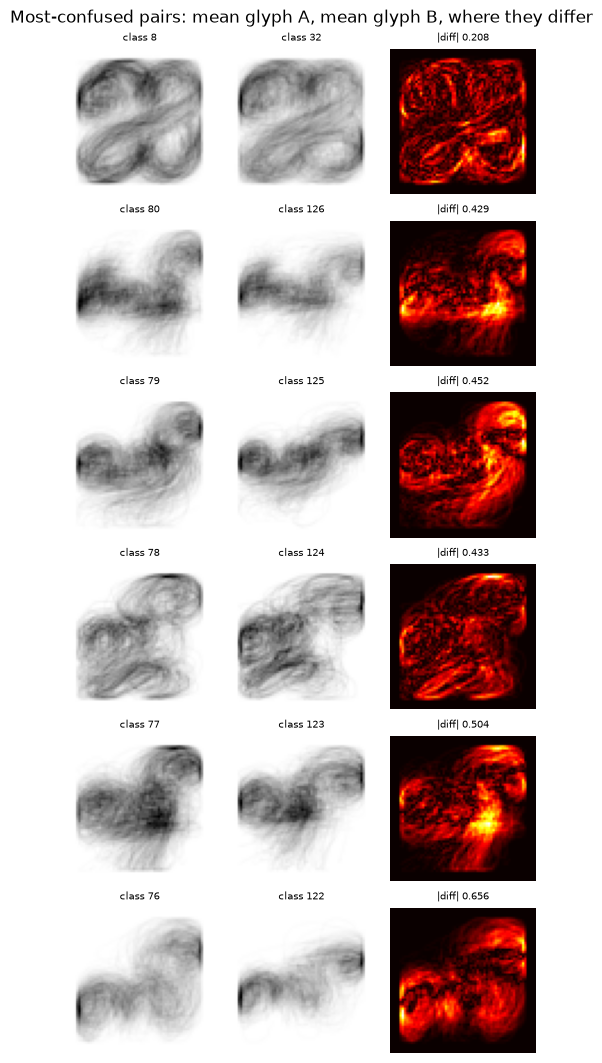

In [98]:
P_va = predict_proba(stage1, Xva); pred_va = P_va.argmax(1)
cm_va = confusion_matrix(yva, pred_va, labels=range(N_CLS))
mean_img = np.stack([(Xtr[ytr == c, 0].astype(np.float32) / 255).mean(0) if (ytr == c).any() else np.zeros((IMG, IMG), np.float32) for c in range(N_CLS)])

def pair_difference(a, b):
    """Normalised shape difference of the two classes' mean images. Small value = almost the same glyph (differ by a small stroke)."""
    return float(np.abs(mean_img[a] - mean_img[b]).sum() / (0.5 * (mean_img[a].sum() + mean_img[b].sum()) + 1e-9))

def top_pairs(cm, k=15):
    sym = cm + cm.T; rows = [(sym[i, j], cm[i, j], cm[j, i], i, j) for i in range(len(cm)) for j in range(i + 1, len(cm)) if sym[i, j] > 0]
    rows = sorted(rows, reverse=True)[:k]
    return pd.DataFrame([dict(class_a=i, class_b=j, a_as_b=ab, b_as_a=ba, total=t, shape_diff=round(pair_difference(i, j), 3)) for t, ab, ba, i, j in rows])

tp = top_pairs(cm_va, 15); print(tp.to_string(index=False)); tp.to_csv(EXP / "top_confused_pairs_val.csv", index=False)

n_show = min(6, len(tp))
fig, ax = plt.subplots(n_show, 3, figsize=(5, 1.8 * n_show), squeeze=False)
for r, row in tp.head(n_show).iterrows():
    a, b = int(row.class_a), int(row.class_b)
    ax[r, 0].imshow(1 - mean_img[a], cmap="gray"); ax[r, 0].set_title(f"class {a}", fontsize=7)
    ax[r, 1].imshow(1 - mean_img[b], cmap="gray"); ax[r, 1].set_title(f"class {b}", fontsize=7)
    ax[r, 2].imshow(np.abs(mean_img[a] - mean_img[b]), cmap="hot"); ax[r, 2].set_title(f"|diff| {row.shape_diff}", fontsize=7)
for a_ in ax.ravel(): a_.axis("off")
plt.suptitle("Most-confused pairs: mean glyph A, mean glyph B, where they differ"); plt.tight_layout(); plt.savefig(EXP / "confused_pairs_diff.png", dpi=120); plt.show()

## 7. Novelty – Confusion-Guided Expert Refinement (CGER)
1. Group classes that the stage-1 model confuses (union-find over the strongest confusion edges, group size ≤ 5).
2. For every group fine-tune a copy of the stage-1 network with a small head over *only that group's classes* (augmentation on).
3. At inference, if the stage-1 top-1 class lies in a group and its confidence < τ, fuse
   `α · p_stage1(renormalised within group) + (1-α) · p_expert`. τ and α are tuned on validation.

In [99]:
def mine_groups(cm, min_pair=2, max_size=5):
    n = len(cm); sym = cm + cm.T
    pairs = sorted([(sym[i, j], i, j) for i in range(n) for j in range(i + 1, n) if sym[i, j] >= min_pair], reverse=True)
    parent, size = list(range(n)), [1] * n
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for _, i, j in pairs:
        a, b = find(i), find(j)
        if a != b and size[a] + size[b] <= max_size: parent[b] = a; size[a] += size[b]
    g = {}
    for k in range(n): g.setdefault(find(k), []).append(k)
    return [sorted(v) for v in g.values() if len(v) > 1]

groups = mine_groups(cm_va, min_pair=2 if not QUICK else 1)
print(f"{len(groups)} confusable groups covering {sum(map(len, groups))} classes"); print(groups[:20])
json.dump(groups, open(EXP / "confusion_groups.json", "w"))

experts = []
for gi, G in enumerate(groups):
    G = list(G); m_tr, m_va = np.isin(ytr, G), np.isin(yva, G)
    loc = {c: i for i, c in enumerate(G)}
    ytr_g = np.array([loc[c] for c in ytr[m_tr]]); yva_g = np.array([loc[c] for c in yva[m_va]]) if m_va.any() else np.array([], int)
    net = copy.deepcopy(stage1); net.head = nn.Linear(net.head.in_features, len(G))
    Xv_g = Xva[m_va] if m_va.any() else Xtr[m_tr][:2]; yv_g = yva_g if m_va.any() else ytr_g[:2]
    exp_model, _ = train_model(f"expert_{gi}", Xtr[m_tr], ytr_g, Xv_g, yv_g, len(G), aug=True, epochs=EPOCHS_EXPERT, lr=1e-3,
                               init=net, bs=min(BS, max(8, m_tr.sum() // 4)), save=False, verbose=False)
    torch.save(exp_model.state_dict(), EXPERTS / f"group_{gi}.pth"); experts.append(exp_model)
print("trained", len(experts), "experts")

def expert_cache(P1, X):
    top1 = P1.argmax(1); cache = []
    for G, ex in zip(groups, experts):
        idx = np.where(np.isin(top1, G))[0]
        cache.append((idx, predict_proba(ex, X[idx]) if len(idx) else np.zeros((0, len(G)))))
    return cache

def fuse(P1, cache, tau, alpha):
    pred = P1.argmax(1).copy(); conf = P1.max(1)
    for G, (idx, Pe) in zip(groups, cache):
        if len(idx) == 0: continue
        sel = conf[idx] < tau
        if not sel.any(): continue
        pg = P1[idx][:, G]; pg = pg / (pg.sum(1, keepdims=True) + 1e-9)
        pred[idx[sel]] = np.array(G)[(alpha * pg + (1 - alpha) * Pe).argmax(1)[sel]]
    return pred

cache_va = expert_cache(P_va, Xva); grid = []
for tau in (0.6, 0.8, 0.9, 0.95, 0.99, 1.01):
    for alpha in (0.0, 0.25, 0.5, 0.75):
        p = fuse(P_va, cache_va, tau, alpha); grid.append(dict(tau=tau, alpha=alpha, val_acc=accuracy_score(yva, p), val_macroF1=macro_f1(yva, p)))
grid = pd.DataFrame(grid).sort_values(["val_macroF1", "alpha"], ascending=False); print(grid.head(8).round(4).to_string(index=False))
TAU, ALPHA = float(grid.iloc[0].tau), float(grid.iloc[0].alpha)
print(f"chosen τ={TAU}, α={ALPHA} | stage-1 val acc {accuracy_score(yva, pred_va):.4f} macroF1 {macro_f1(yva, pred_va):.4f}")
grid.to_csv(EXP / "cger_tuning_val.csv", index=False)

30 confusable groups covering 89 classes
[[2, 35, 37, 58, 60], [6, 7, 9, 10], [8, 32], [13, 82, 84, 88, 133], [27, 29, 120], [33, 153], [36, 59], [39, 43, 62, 66, 89], [40, 63], [41, 47, 64, 70], [42, 65], [44, 67], [45, 68], [46, 69], [48, 71], [49, 72], [50, 73], [51, 74], [52, 75], [53, 76, 122, 127]]
trained 30 experts
 tau  alpha  val_acc  val_macroF1
0.95   0.00   0.9414       0.9366
0.90   0.00   0.9414       0.9366
0.99   0.00   0.9413       0.9365
1.01   0.00   0.9413       0.9365
0.80   0.00   0.9406       0.9358
0.99   0.25   0.9407       0.9356
1.01   0.25   0.9407       0.9356
0.60   0.00   0.9400       0.9355
chosen τ=0.95, α=0.0 | stage-1 val acc 0.9359 macroF1 0.9319


## 8. FINAL evaluation on the official test set (run once)
Everything above was chosen on validation only. This cell reports stage-1 (baseline) and CGER side by side.

                          accuracy  macro_F1  errors
stage-1 (resnet18_ft)       0.9367    0.9325  1704.0
CGER (stage-1 + experts)    0.9340    0.9298  1778.0
stage-1 top-5 accuracy: 0.9961
CGER corrected 184 stage-1 errors and introduced 258 new ones
              precision  recall  f1-score    support
accuracy         0.9340  0.9340    0.9340      0.934
macro avg        0.9349  0.9294    0.9298  26926.000
weighted avg     0.9382  0.9340    0.9339  26926.000

10 weakest classes (CGER, by F1):
     precision  recall  f1-score  support
124      0.554   0.490     0.520    104.0
78       0.493   0.713     0.583    101.0
123      0.582   0.586     0.584    152.0
126      0.571   0.651     0.608    166.0
122      0.664   0.567     0.612    157.0
129      0.743   0.529     0.618    104.0
127      0.854   0.506     0.636    162.0
125      0.703   0.584     0.638    166.0
80       0.593   0.736     0.657    178.0
128      0.901   0.526     0.664    156.0


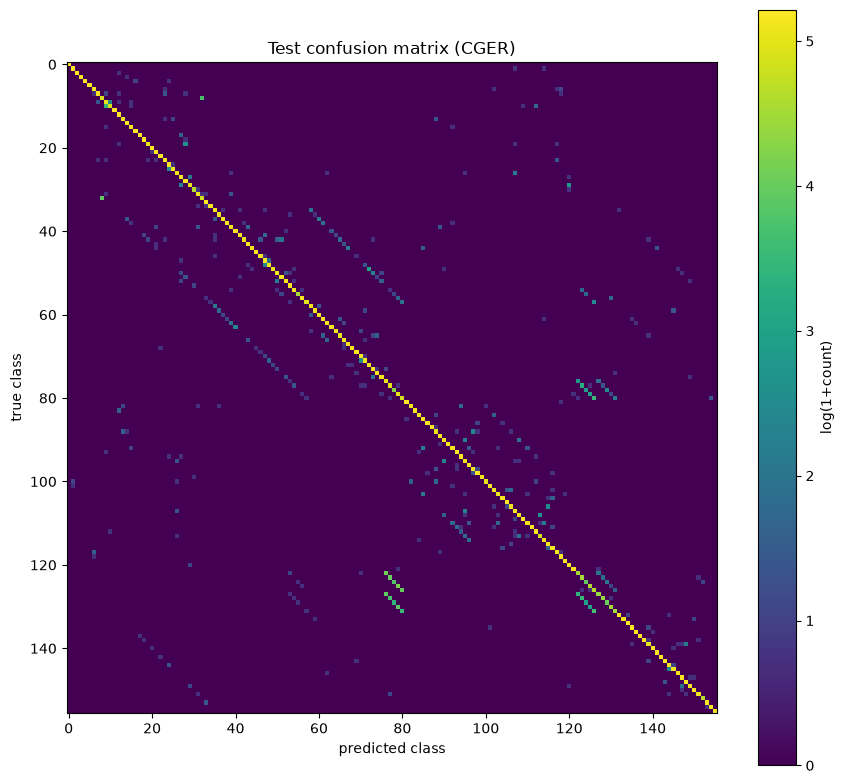

 class_a  class_b  a_as_b  b_as_a  total  shape_diff
       8       32      39      49     88       0.208
      79      125      20      66     86       0.452
      80      126      33      52     85       0.429
      77      123      26      56     82       0.504
      76      122      15      58     73       0.656
      78      124      17      43     60       0.433
      76      127       6      50     56       0.639
      79      130       2      49     51       0.487
      77      128       3      40     43       0.556
       9       10      11      31     42       0.299
      78      129      12      29     41       0.492
     126      131       4      37     41       0.280
      80      131       8      32     40       0.514
     123      128       6      32     38       0.287
     122      127       7      29     36       0.308


In [100]:
P_te = predict_proba(stage1, Xte); pred_s1 = P_te.argmax(1)
pred_cg = fuse(P_te, expert_cache(P_te, Xte), TAU, ALPHA)
top5 = float(np.mean([yte[i] in np.argsort(-P_te[i])[:5] for i in range(len(yte))]))
res = pd.DataFrame({m: dict(accuracy=accuracy_score(yte, p), macro_F1=macro_f1(yte, p), errors=int((p != yte).sum()))
                    for m, p in {f"stage-1 ({best_name})": pred_s1, "CGER (stage-1 + experts)": pred_cg}.items()}).T
print(res.round(4)); print("stage-1 top-5 accuracy: %.4f" % top5); res.to_csv(EXP / "test_results.csv")
fixed = int(((pred_s1 != yte) & (pred_cg == yte)).sum()); broken = int(((pred_s1 == yte) & (pred_cg != yte)).sum())
print(f"CGER corrected {fixed} stage-1 errors and introduced {broken} new ones")

for tag, p in (("stage1", pred_s1), ("cger", pred_cg)):
    rep = pd.DataFrame(classification_report(yte, p, labels=range(N_CLS), output_dict=True, zero_division=0)).T
    rep.to_csv(EXP / f"per_class_report_test_{tag}.csv")
rep = pd.read_csv(EXP / "per_class_report_test_cger.csv", index_col=0)
print(rep.tail(3).round(4)); print("\n10 weakest classes (CGER, by F1):"); print(rep.iloc[:N_CLS].sort_values("f1-score").head(10).round(3))

cm_te = confusion_matrix(yte, pred_cg, labels=range(N_CLS)); np.save(EXP / "confusion_matrix_test.npy", cm_te)
plt.figure(figsize=(9, 8)); plt.imshow(np.log1p(cm_te), cmap="viridis"); plt.colorbar(label="log(1+count)")
plt.xlabel("predicted class"); plt.ylabel("true class"); plt.title("Test confusion matrix (CGER)"); plt.tight_layout()
plt.savefig(EXP / "confusion_matrix_test.png", dpi=130); plt.show()
tp_te = top_pairs(cm_te, 15); print(tp_te.to_string(index=False)); tp_te.to_csv(EXP / "top_confused_pairs_test.csv", index=False)

## 9. Misclassified test images (for the report's explanation)
Each panel: true → predicted, the confusion pair's shape difference (small = nearly identical glyph) and whether the pair is in a mined group.

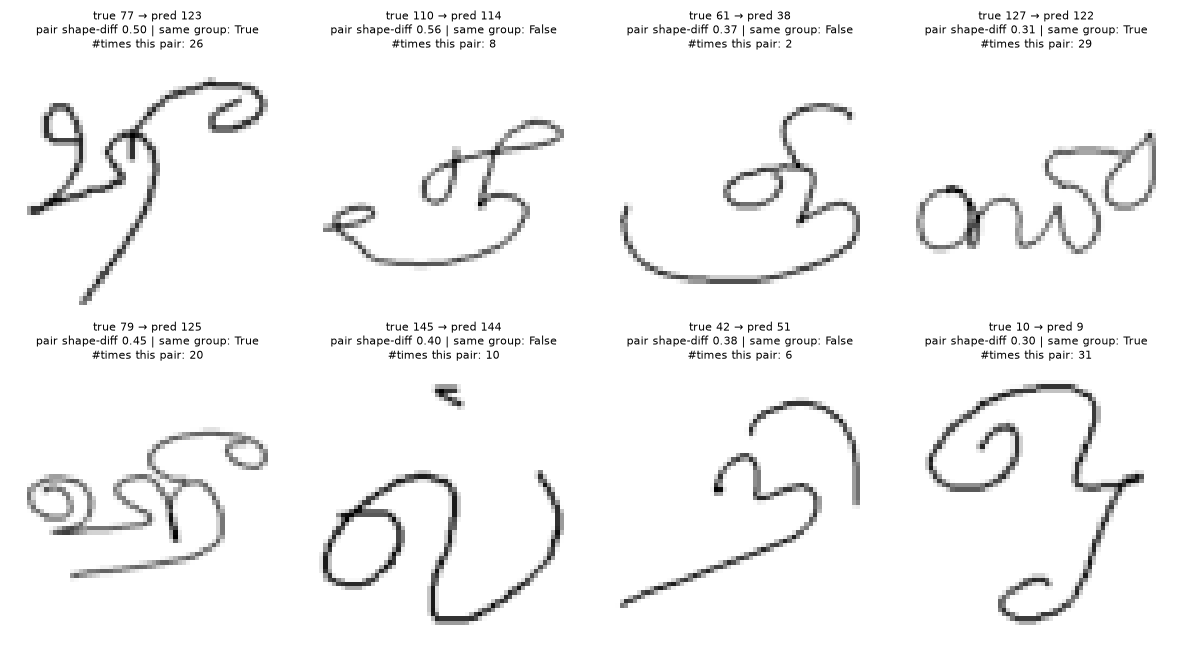

write the likely cause for each panel in the report: small stroke/dot/loop difference, similar overall shape, sloppy/broken stroke, ambiguous writer style.


In [101]:
wrong = np.where(pred_cg != yte)[0]; rng = np.random.RandomState(SEED)
pair_counts = {}
for i in wrong: pair_counts[(yte[i], pred_cg[i])] = pair_counts.get((yte[i], pred_cg[i]), 0) + 1
chosen, seen = [], set()
for i in rng.permutation(wrong):                                    # prefer diverse pairs
    k = (yte[i], pred_cg[i])
    if k not in seen: seen.add(k); chosen.append(i)
    if len(chosen) == 8: break
fig, ax = plt.subplots(2, 4, figsize=(12, 6.5))
for a_, i in zip(ax.ravel(), chosen):
    t, p_ = int(yte[i]), int(pred_cg[i]); in_g = any(t in G and p_ in G for G in groups)
    a_.imshow(255 - Xte[i, 0], cmap="gray"); a_.axis("off")
    a_.set_title(f"true {t} → pred {p_}\npair shape-diff {pair_difference(t, p_):.2f} | same group: {in_g}\n#times this pair: {pair_counts[(t, p_)]}", fontsize=8)
plt.tight_layout(); plt.savefig(EXP / "misclassified_examples.png", dpi=130); plt.show()
print("write the likely cause for each panel in the report: small stroke/dot/loop difference, similar overall shape, sloppy/broken stroke, ambiguous writer style.")

In [102]:
"""Rebuild report figures/numbers for the FINAL model from files saved by the notebook (no retraining).
Run from the project folder:   python report_figs_standalone.py
Needs: outputs/best_<FINAL>.pth, outputs/cache_64.npz, outputs/experiments/hist_<FINAL>.json,
       train_metadata.csv, test_metadata.csv  (all written by the notebook)."""
import os, json, math, platform
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torchvision, sklearn
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

ROOT = Path(os.environ.get("PS39_ROOT", ".")).resolve()
FINAL = os.environ.get("FINAL", "resnet18_ft")            # model name used in outputs/best_<FINAL>.pth
KIND = "resnet" if FINAL.startswith("resnet") else "cnn"
SEED, IMG = 42, 64
OUT = ROOT / "outputs"; EXP = OUT / "experiments"; FIG = EXP / "report_figs"; FIG.mkdir(parents=True, exist_ok=True)
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.titlesize": 9})

# ---------- data (same order and split as the notebook) ----------
tr_meta = pd.read_csv(ROOT / "train_metadata.csv"); te_meta = pd.read_csv(ROOT / "test_metadata.csv")
z = np.load(OUT / f"cache_{IMG}.npz"); Xall, Xte = z["Xtr"], z["Xte"]
assert len(Xall) == len(tr_meta) and len(Xte) == len(te_meta), "cache and metadata do not match"
yall, yte = tr_meta.label.values, te_meta.label.values; N_CLS = int(max(yall.max(), yte.max()) + 1)
tr_idx, va_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(Xall, yall, groups=tr_meta.writer.values))
Xtr, ytr = Xall[tr_idx], yall[tr_idx]

# ---------- model (same definitions as the notebook) ----------
class CNN(nn.Module):
    def __init__(s, n_cls, widths=(32, 64, 128, 256), p=0.4, img=IMG):
        super().__init__(); L, c = [], 1
        for o in widths:
            L += [nn.Conv2d(c, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True),
                  nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(True), nn.MaxPool2d(2)]; c = o
        s.features = nn.Sequential(*L); f = img // (2 ** len(widths))
        s.embed = nn.Sequential(nn.Flatten(), nn.Linear(c * f * f, 256), nn.BatchNorm1d(256), nn.ReLU(True), nn.Dropout(p)); s.head = nn.Linear(256, n_cls)
    def forward(s, x): return s.head(s.embed(s.features(x)))

class ResNetWrap(nn.Module):
    def __init__(s, n_cls):
        super().__init__(); net = torchvision.models.resnet18(weights=None)      # weights come from the saved checkpoint
        net.conv1 = nn.Conv2d(1, 64, 3, 1, 1, bias=False); net.maxpool = nn.Identity(); net.fc = nn.Identity()
        s.net, s.head = net, nn.Linear(512, n_cls)
    def forward(s, x): return s.head(s.net(x))

model = (CNN(N_CLS) if KIND == "cnn" else ResNetWrap(N_CLS)).to(DEV)
model.load_state_dict(torch.load(OUT / f"best_{FINAL}.pth", map_location=DEV)); model.eval()

@torch.no_grad()
def predict_proba(X, bs=512):
    out = []
    for i in range(0, len(X), bs):
        xb = torch.from_numpy(X[i:i + bs]).to(DEV).float().div_(255)
        with torch.autocast(DEV.type, enabled=DEV.type == "cuda"): out.append(F.softmax(model(xb).float(), 1).cpu())
    return torch.cat(out).numpy()

P_te = predict_proba(Xte); pred = P_te.argmax(1)
def macro_f1(y, p): return f1_score(y, p, average="macro", labels=np.unique(y), zero_division=0)

# ---------- numbers for Table 2 ----------
print(f"[{FINAL}] TEST accuracy {100*accuracy_score(yte, pred):.2f} | macro F1 {100*macro_f1(yte, pred):.2f} | "
      f"top-5 {100*np.mean([yte[i] in np.argsort(-P_te[i])[:5] for i in range(len(yte))]):.2f} | errors {int((pred != yte).sum())} of {len(yte)}")
rep = pd.DataFrame(classification_report(yte, pred, labels=range(N_CLS), output_dict=True, zero_division=0)).T.iloc[:N_CLS]; rep.index = range(N_CLS)
rep.to_csv(FIG / "per_class_report_test_final.csv")
print("Five lowest-F1 classes:"); print(rep.sort_values("f1-score").head(5)[["precision", "recall", "f1-score", "support"]].round(2))

# ---------- Fig. 1 ----------
h = json.load(open(EXP / f"hist_{FINAL}.json")); ep = np.arange(1, len(h["val_acc"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.6))
ax[0].plot(ep, h["train_loss"], label="train"); ax[0].plot(ep, h["val_loss"], label="validation"); ax[0].set(xlabel="epoch", ylabel="loss", title="Loss")
ax[1].plot(ep, 100 * np.array(h["train_acc"]), label="train (augmented batches)"); ax[1].plot(ep, 100 * np.array(h["val_acc"]), label="validation")
ax[1].set(xlabel="epoch", ylabel="accuracy (%)", title="Accuracy")
for a in ax: a.legend(frameon=False, fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(FIG / "fig1_learning_curves.png", dpi=300); plt.close()

# ---------- Fig. 2 ----------
cm = confusion_matrix(yte, pred, labels=range(N_CLS)); np.save(FIG / "confusion_matrix_test_final.npy", cm)
fig, ax = plt.subplots(figsize=(3.6, 3.4)); im = ax.imshow(np.log1p(cm), cmap="viridis")
fig.colorbar(im, fraction=0.046, pad=0.03).set_label("log(1 + count)"); ax.set(xlabel="predicted class", ylabel="true class")
plt.tight_layout(); plt.savefig(FIG / "fig2_confusion_matrix.png", dpi=300); plt.close()

# ---------- most-confused pairs ----------
mean_img = np.stack([(Xtr[ytr == c, 0].astype(np.float32) / 255).mean(0) if (ytr == c).any() else np.zeros((IMG, IMG), np.float32) for c in range(N_CLS)])
def pair_difference(a, b): return float(np.abs(mean_img[a] - mean_img[b]).sum() / (0.5 * (mean_img[a].sum() + mean_img[b].sum()) + 1e-9))
sym = cm + cm.T
rows = sorted([(sym[i, j], cm[i, j], cm[j, i], i, j) for i in range(N_CLS) for j in range(i + 1, N_CLS) if sym[i, j] > 0], reverse=True)[:15]
pairs = pd.DataFrame([dict(class_a=i, class_b=j, a_as_b=ab, b_as_a=ba, total=t, shape_diff=round(pair_difference(i, j), 3)) for t, ab, ba, i, j in rows])
pairs.to_csv(FIG / "top_confused_pairs_final.csv", index=False); print("Most-confused pairs (test):"); print(pairs.head(10).to_string(index=False))

# ---------- Fig. 3: real samples of the top-3 pairs ----------
K, n = min(3, len(pairs)), 6; rng = np.random.RandomState(0)
fig, axes = plt.subplots(2 * K, n, figsize=(n * 0.95, 2 * K * 1.0), squeeze=False)
for r, (a, b) in enumerate(zip(pairs.class_a.head(K).astype(int), pairs.class_b.head(K).astype(int))):
    for k, c in enumerate((a, b)):
        idx = np.where(ytr == c)[0]; sel = rng.choice(idx, min(n, len(idx)), replace=False)
        for j in range(n):
            axx = axes[2 * r + k, j]; axx.axis("off")
            if j < len(sel): axx.imshow(255 - Xtr[sel[j], 0], cmap="gray")
            if j == 0: axx.set_title(f"class {c}", fontsize=7, loc="left")
plt.tight_layout(); plt.savefig(FIG / "fig3_confused_pairs_samples.png", dpi=300); plt.close()

# ---------- Fig. 4: misclassified test images ----------
wrong = np.where(pred != yte)[0]; rng = np.random.RandomState(SEED); pc = {}
for i in wrong: pc[(yte[i], pred[i])] = pc.get((yte[i], pred[i]), 0) + 1
chosen, seen = [], set()
for i in rng.permutation(wrong):
    k = (yte[i], pred[i])
    if k not in seen: seen.add(k); chosen.append(i)
    if len(chosen) == 8: break
fig, axes = plt.subplots(2, 4, figsize=(7.0, 3.8))
for axx in axes.ravel(): axx.axis("off")
for axx, i in zip(axes.ravel(), chosen):
    t, p_ = int(yte[i]), int(pred[i]); axx.imshow(255 - Xte[i, 0], cmap="gray"); axx.set_title(f"true {t} → pred {p_}\n(this pair: {pc[(t, p_)]}×)", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "fig4_misclassified.png", dpi=300); plt.close()

print("Saved to", FIG)
print("python", platform.python_version(), "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| sklearn", sklearn.__version__, "| CUDA", torch.version.cuda, "| device", DEV, "| seed", SEED)

[resnet18_ft] TEST accuracy 93.67 | macro F1 93.25 | top-5 99.61 | errors 1704 of 26926
Five lowest-F1 classes:
     precision  recall  f1-score  support
124       0.53    0.45      0.49    104.0
125       0.65    0.54      0.59    166.0
78        0.48    0.83      0.61    101.0
123       0.68    0.56      0.61    152.0
122       0.67    0.57      0.62    157.0
Most-confused pairs (test):
 class_a  class_b  a_as_b  b_as_a  total  shape_diff
       8       32      48      43     91       0.208
      79      125      16      70     86       0.452
      80      126      12      62     74       0.429
      77      123      14      57     71       0.504
      78      124      17      52     69       0.433
      76      122      16      50     66       0.656
      77      128      14      40     54       0.556
      80      131       9      40     49       0.514
      79      130       6      42     48       0.487
      76      127      13      33     46       0.639
Saved to C:\Users\Shreya\